# Phase 8: Initial Regression Study

**Frozen historical report.** The following Phase 8 cells, plots, captions and corrections are copied unchanged from the completed main notebook. This study compared selected policies; it did not establish matched retention. Its unfavorable acquisition result remains evidence, not a discarded experiment. Original progress timestamps describe that completed run.

[Main results and Phase 8.1](fisher_memory_results.ipynb) | [Original protocol](plan15.md)

Run: `cache/mnist_experiment/plan15/regression_phase8_v2`. Source revision: `4337a6f2b095f327b00acab9dac8bdd171123ef0`. Scientific source hash: `cdc2da2dafb1d9868926c96391165b187074c71697a96c7633dc359c62d728cf`. Source-notebook and preserved-cell checksums are recorded in notebook metadata. Do not refresh this snapshot in place; publish any later historical analysis separately.

**Phase 8 progress** | 8E complete: completed | 36/36 planned units | 12/12 complete confirmation pairs | 2.93/20.0 active h | remaining forecast: 0.00 h

Shared storage: 4.44 GB used / 500 GB cap (this study 0.235 GB + external 4.21 GB); 0 GB reserved. Heartbeat: 2026-10-25T05:39:56.294954+00:00; revision: cdc2da2dafb1. Development is exploratory; confirmation intervals require the entire frozen cohort.

## Phase 8: Regression, Allocation And Sample Efficiency

**Question:** under limited new data and compute, how should replay capacity and replay work be allocated, and can FD KL improve learning while retaining near-upright prediction?

Each paired replica starts from the same pretrained scalar model (287 LTM and 135 STM parameters); both memory blocks update online. Novel counts exclude pretraining and accompanying background observations.

$C$ is logical FIFO replay capacity; $b$ is the fixed resident subset per solve, not total closure passes. $n$ counts unique novel arrivals. $R^D(n)$ is predictive MSE on a fixed held-out image/angle panel; $A^D(N)=N^{-1}\sum_{n=1}^{N}R^D(n)$ averages over novel-sample budgets, excluding initialization. Every n checkpoint follows an accepted update with exactly n novel observations. Gaussian NLL uses a fixed 45-degree scale and contains no regularizers. New-domain learning and near-upright retention are evaluated separately. Neither evaluation panel enters training, replay, or Fisher estimation; development selects policies, and separate confirmation panels never tune them. The final contrast compares separately selected policies under the same constraints, not an isolated equal-(C,b) FD effect.

**Status:** completed

[Supplementary diagnostics](../cache/mnist_experiment/plan15/regression_phase8_v2/reports/phase8-diagnostics-v2.html): renderer examples, development risk/compute frontiers and per-digit prediction errors.

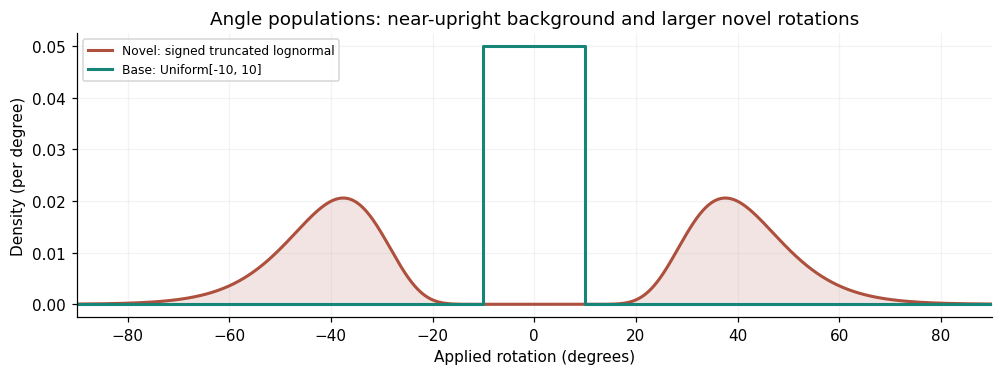

The drip increases the novel-component probability while retaining near-upright arrivals. Rejection above 90 degrees removes about 0.059% of magnitude mass; there is no clipping or endpoint atom.

### Calibration

| Check | Development result |
| --- | --- |
| Initialization | Better than zero predictor in every pilot replica |
| Solver/FD numerical checks | FD value and gradient checks passed; solver gaps disclosed |
| Ridge multiplier c | 10 |
| FD strength / step | 264 / 0.01 |
| Measured FD/replay learning-time ratio | 1.77 |
| Seconds/arrival allowance | 0.0585 |

**Retention warning:** No development policy met the base-retention tolerance; least violation carried forward. The allocation study continues with the least-violating valid reference policy.

![Development only. Risk maps share a color scale; positive paired differences favor FD. n is the replica count (paired intersection in the difference map); unequal sets are not pooled as paired evidence. ! marks a retention/cost violation. Missing and invalid cells remain distinct. Visual review: Visually reviewed: larger capacity trades new learning for retention; paired FD risk differences are consistently unfavorable. Selected FD (256,16) meets the development mean guard; replay (256,4) narrowly misses it (1.014 degrees) and cont](attachment:allocation.png)

Development only. Risk maps share a color scale; positive paired differences favor FD. n is the replica count (paired intersection in the difference map); unequal sets are not pooled as paired evidence. ! marks a retention/cost violation. Missing and invalid cells remain distinct. Visual review: Visually reviewed: larger capacity trades new learning for retention; paired FD risk differences are consistently unfavorable. Selected FD (256,16) meets the development mean guard; replay (256,4) narrowly misses it (1.014 degrees) and cont
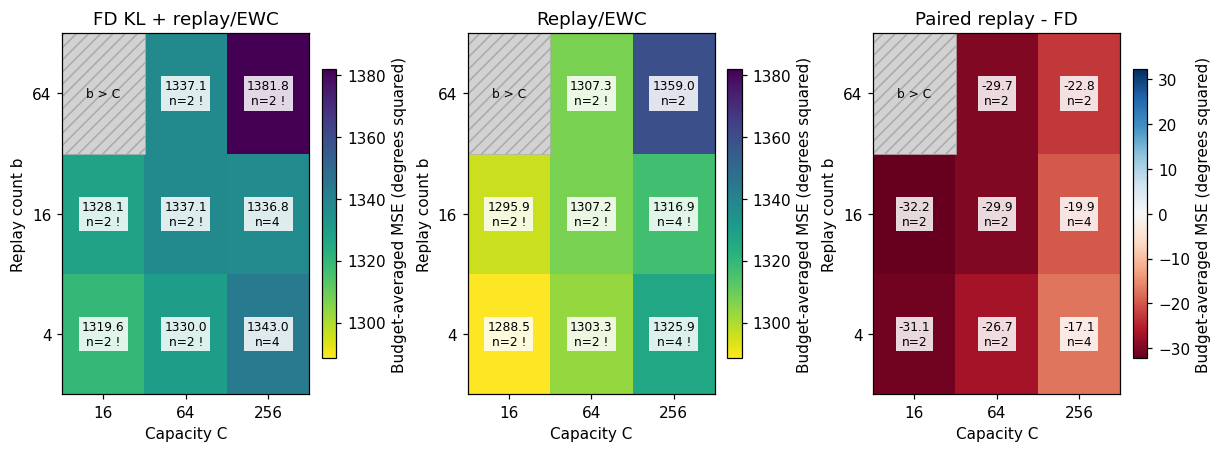

![12 complete paired replicas; pointwise nominal 95% whole-replica bootstrap bands, not simultaneous bands. RMSE is the square root of mean MSE, not mean replica RMSE. Fixed held-out panels never enter fitting, replay, FD or Fisher estimation. The two domains use different labeled y scales.](attachment:fresh.png)

12 complete paired replicas; pointwise nominal 95% whole-replica bootstrap bands, not simultaneous bands. RMSE is the square root of mean MSE, not mean replica RMSE. Fixed held-out panels never enter fitting, replay, FD or Fisher estimation. The two domains use different labeled y scales.
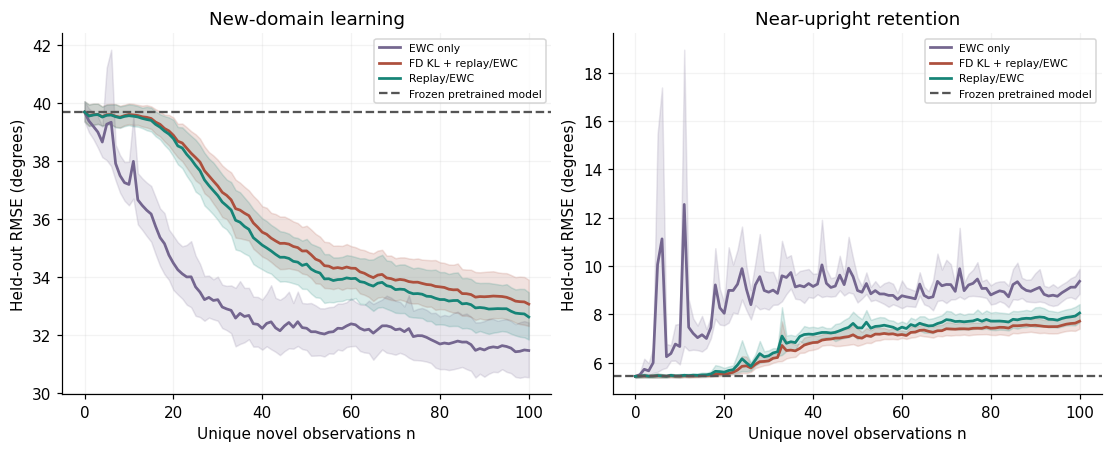

![Nominal paired 95% intervals resample complete trajectories, not timepoints. Acquisition averages predictive MSE over n=1,...,N; initialization is excluded. Retention is mean per-replica sqrt(A_base) minus frozen RMSE. Retired panel: up to the first eight novel arrivals per replica, measured only after actual retirement. Each point averages supplied audit predictions at that exact observed age; the lower panel shows contributing prediction counts, not independent sample sizes. FD KL + replay/EWC: 96 unique retired images; Replay/EWC: 96 unique retired images; EWC only: 96 unique retired images. Different capacities imply different retirement times and available cohorts: this is descriptive training-data retention, not a paired causal contrast or held-out generalization.](attachment:effects.png)

Nominal paired 95% intervals resample complete trajectories, not timepoints. Acquisition averages predictive MSE over n=1,...,N; initialization is excluded. Retention is mean per-replica sqrt(A_base) minus frozen RMSE. Retired panel: up to the first eight novel arrivals per replica, measured only after actual retirement. Each point averages supplied audit predictions at that exact observed age; the lower panel shows contributing prediction counts, not independent sample sizes. FD KL + replay/EWC: 96 unique retired images; Replay/EWC: 96 unique retired images; EWC only: 96 unique retired images. Different capacities imply different retirement times and available cohorts: this is descriptive training-data retention, not a paired causal contrast or held-out generalization.
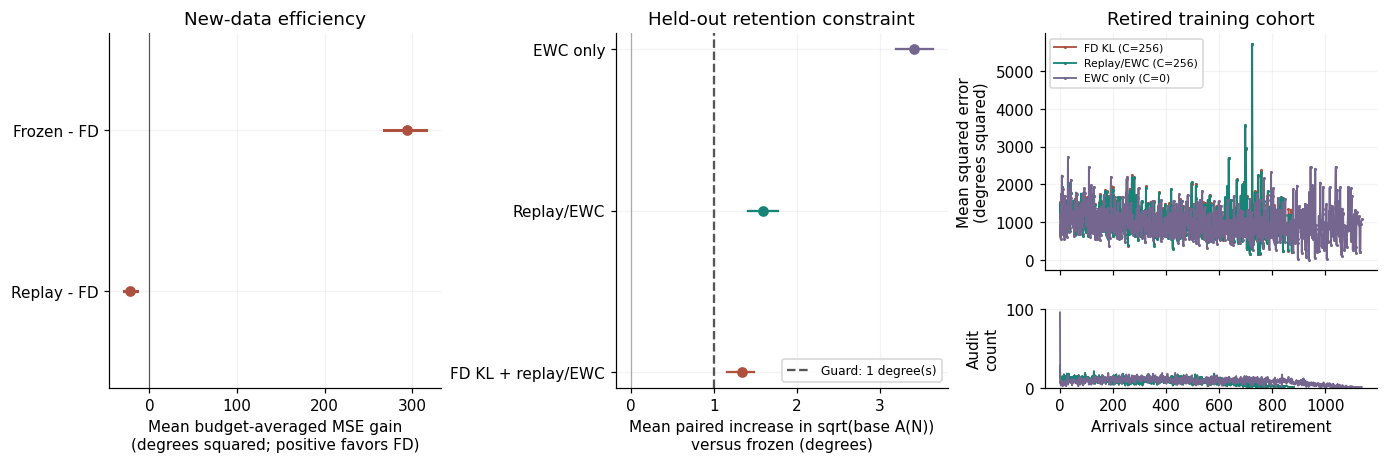

![FD KL + replay/EWC at n=75: 820.3 total arrivals, 36.4 learning seconds; Replay/EWC at n=100: 1048.5 total arrivals, 27.6 learning seconds. Counts exclude shared pretraining but retain accompanying background exposure. This is not a causal label-only effect or a first-passage samples-saved estimate. Development did not identify a smaller-budget match; n_F=75 is the prespecified fallback probe. FD(n_F) - replay(N) MSE: 79.8 [59.8, 101].](attachment:equivalence.png)

FD KL + replay/EWC at n=75: 820.3 total arrivals, 36.4 learning seconds; Replay/EWC at n=100: 1048.5 total arrivals, 27.6 learning seconds. Counts exclude shared pretraining but retain accompanying background exposure. This is not a causal label-only effect or a first-passage samples-saved estimate. Development did not identify a smaller-budget match; n_F=75 is the prespecified fallback probe. FD(n_F) - replay(N) MSE: 79.8 [59.8, 101].
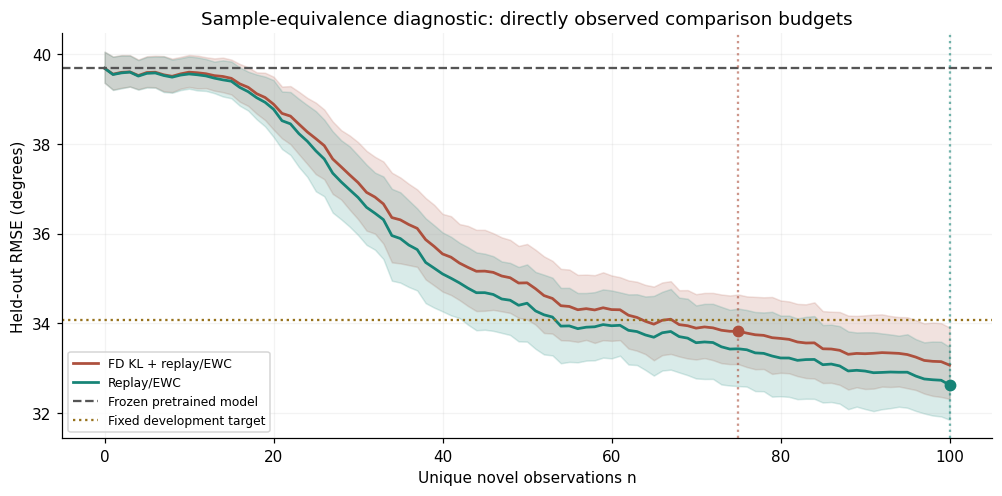

**Significant corrections**

**Phase 8 numerical repair: Trace-preserving rank-eight spectral compression.** Legacy Lanczos lost basis orthogonality on nearly rank-one Fisher matrices, duplicating curvature and causing an exploding archive and ridge scale. v1 development and partial confirmation are superseded and retained. v2 uses fresh component seeds and a new scientific identity. Validation: Rank-deficient trace/diagonal conservation, repeated-update bounds, PSD and CPU/CUDA recovery are recorded in the v2 repair acceptance artifacts.

Full provenance remains in the study's decision artifacts.

### Conclusion

| Question | Mean [nominal 95% interval] | Interpretation |
| --- | --- | --- |
| Budget-averaged replay - FD MSE | -21.9 [-28.4, -14.5] | supports replay-policy advantage |
| Frozen - FD MSE | 294 [268, 316] | supports useful acquisition |
| FD(75) - replay(100) MSE | 79.8 [59.8, 101] | FD at the smaller budget is worse |
| FD base RMSE increase (degrees) | 1.33 [1.16, 1.49] | retention guard violated |

Frozen replay settings: FD KL + replay/EWC: C=256, b=16; Replay/EWC: C=256, b=4; EWC only: C=0, b=0.

FD: 0.0456 learning seconds per arrival; within measured mean-cost envelope. Peak VRAM 0.0759 GB. 1/12 paired replicas favor FD on budget-averaged new-domain risk. Practical success requires acquisition, retention and resource feasibility together. Input supply is assumed overlap-able; offloading engineering and large-network timing extrapolation are excluded.

Independent paired replicas and adequate squared-error moments; nominal intervals conditional on benchmark panels and frozen recipes, not familywise inference.